### Import libraries:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

### Load the dataset:

In [2]:
df_user_engagement = pd.read_csv("../data/user_engagement.csv")

### Explore the dataset:

In [3]:
df_user_engagement.head()

,user_id,active_days,total_events,total_sessions,total_api_requests,successful_api_requests,failed_api_requests,api_success_rate_percentage,first_activity_date,last_activity_date,activity_lifespan_days,engagement_segment
0,2993,1,1,1,0,0,0,NaN,2026-01-07,2026-01-07,0,Very Low Engagement
1,6905,1,1,1,0,0,0,NaN,2024-12-18,2024-12-18,0,Very Low Engagement
2,3503,1,1,1,0,0,0,NaN,2024-08-02,2024-08-02,0,Very Low Engagement
3,9846,1,1,1,0,0,0,NaN,2025-02-13,2025-02-13,0,Very Low Engagement
4,6294,1,1,1,283,266,17,93.99,2025-08-11,2025-08-11,0,Very Low Engagement


In [4]:
df_user_engagement.shape

(9999, 12)

In [5]:
df_user_engagement.columns

Index(['user_id', 'active_days', 'total_events', 'total_sessions',
       'total_api_requests', 'successful_api_requests', 'failed_api_requests',
       'api_success_rate_percentage', 'first_activity_date',
       'last_activity_date', 'activity_lifespan_days', 'engagement_segment'],
      dtype='str')

In [6]:
df_user_engagement.info()

<class 'pandas.DataFrame'>
RangeIndex: 9999 entries, 0 to 9998
Data columns (total 12 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   user_id                      9999 non-null   int64  
 1   active_days                  9999 non-null   int64  
 2   total_events                 9999 non-null   int64  
 3   total_sessions               9999 non-null   int64  
 4   total_api_requests           9999 non-null   int64  
 5   successful_api_requests      9999 non-null   int64  
 6   failed_api_requests          9999 non-null   int64  
 7   api_success_rate_percentage  9924 non-null   float64
 8   first_activity_date          9999 non-null   str    
 9   last_activity_date           9999 non-null   str    
 10  activity_lifespan_days       9999 non-null   int64  
 11  engagement_segment           9999 non-null   str    
dtypes: float64(1), int64(8), str(3)
memory usage: 1.3 MB


In [7]:
df_user_engagement.describe().T

,count,mean,std,min,25%,50%,75%,max
user_id,9999.0,5000.026803,2886.652191,1.0,2500.5,5000.00,7499.50,10000.0
active_days,9999.0,12.512951,4.493333,1.0,9.0,12.00,15.00,32.0
total_events,9999.0,8.000800,2.828321,1.0,6.0,8.00,10.00,19.0
total_sessions,9999.0,8.000800,2.828321,1.0,6.0,8.00,10.00,19.0
total_api_requests,9999.0,2523.320832,1297.480415,0.0,1588.5,2391.00,3302.00,8463.0
successful_api_requests,9999.0,2397.182818,1232.707649,0.0,1508.0,2273.00,3137.50,8049.0
failed_api_requests,9999.0,126.138014,65.731956,0.0,79.0,120.00,165.00,427.0
api_success_rate_percentage,9924.0,95.003779,0.548763,87.8,94.7,95.01,95.31,100.0
activity_lifespan_days,9999.0,150.845785,23.605806,0.0,141.0,157.00,167.00,180.0


### Analyze engagement segments:

#### calculate the number of users in each segment

In [8]:
engagement_counts = df_user_engagement[
    "engagement_segment"
].value_counts()

display(engagement_counts)

engagement_segment
Moderately Engaged     6685
Low Engagement         2569
Highly Engaged          705
Very Low Engagement      40
Name: count, dtype: int64

#### Calculate the percentage:

In [9]:
engagement_percentages = (
    df_user_engagement["engagement_segment"]
    .value_counts(normalize=True) * 100
)

display(engagement_percentages.round(2))

engagement_segment
Moderately Engaged     66.86
Low Engagement         25.69
Highly Engaged          7.05
Very Low Engagement     0.40
Name: proportion, dtype: float64

### Visualize the distribution:

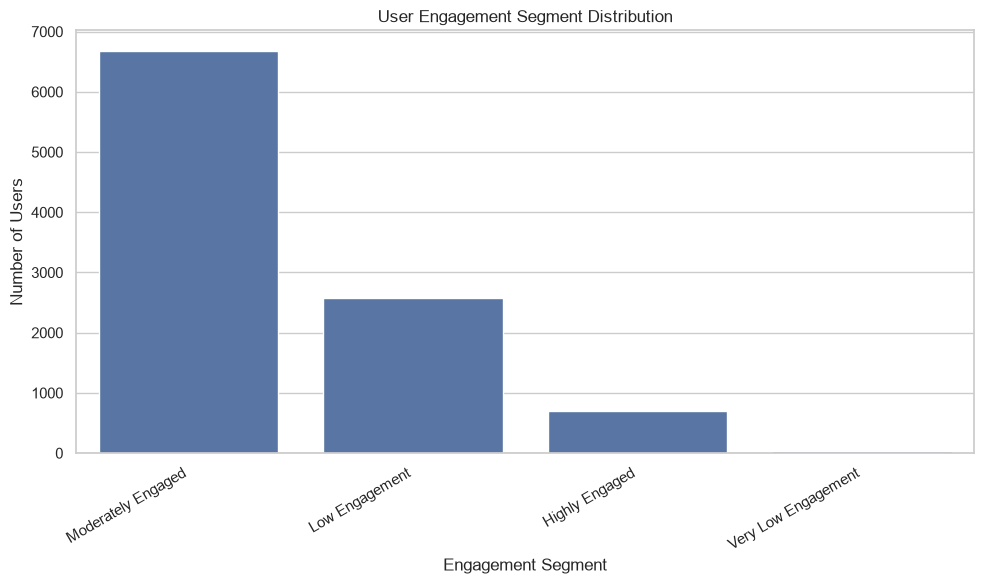

In [10]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df_user_engagement,
    x="engagement_segment",
    order=df_user_engagement["engagement_segment"].value_counts().index
)

plt.title("User Engagement Segment Distribution")
plt.xlabel("Engagement Segment")
plt.ylabel("Number of Users")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()

### Analyze user activity:

#### Check whether these columns exist:

In [11]:
activity_columns = [
    "active_days",
    "total_events",
    "total_sessions",
    "total_api_requests"
]

available_activity_columns = [
    col for col in activity_columns
    if col in df_user_engagement.columns
]

print(available_activity_columns)

['active_days', 'total_events', 'total_sessions', 'total_api_requests']


#### Calculate average activity:

In [12]:
activity_summary = df_user_engagement[
    available_activity_columns
].agg(["mean", "median", "min", "max", "std"]).T

display(activity_summary)

,mean,median,min,max,std
active_days,12.512951,12.0,1.0,32.0,4.493333
total_events,8.000800,8.0,1.0,19.0,2.828321
total_sessions,8.000800,8.0,1.0,19.0,2.828321
total_api_requests,2523.320832,2391.0,0.0,8463.0,1297.480415


### Compare activity across engagement segments:

In [13]:
segment_activity = df_user_engagement.groupby(
    "engagement_segment"
)[available_activity_columns].mean()

display(segment_activity)

,active_days,total_events,total_sessions,total_api_requests
engagement_segment,,,,
Highly Engaged,21.846809,13.573050,13.573050,4745.775887
Low Engagement,7.223822,4.840794,4.840794,1314.176333
Moderately Engaged,13.626328,8.667165,8.667165,2767.741660
Very Low Engagement,1.625000,1.375000,1.375000,161.025000


#### Visualize average API requests by segment, if the column exists

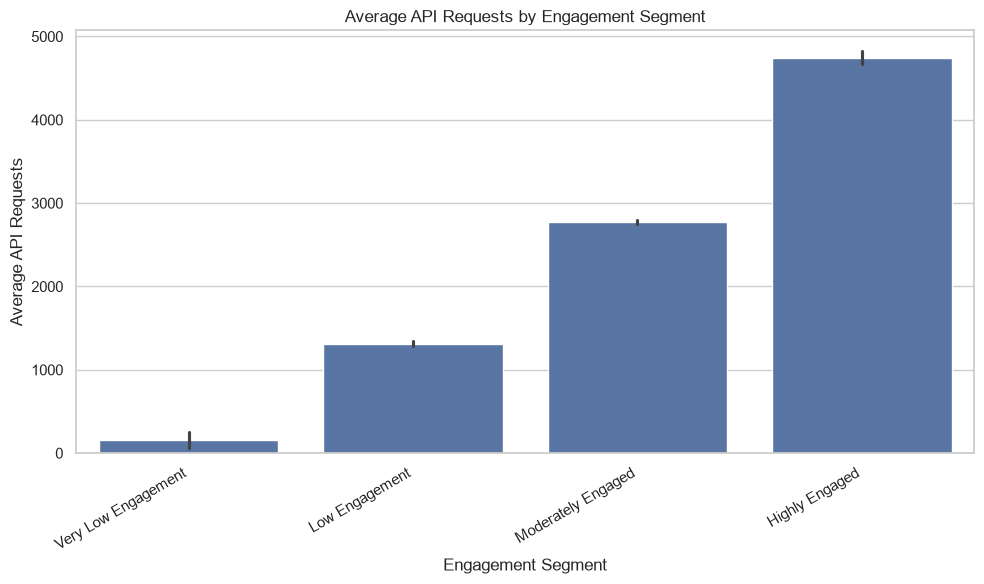

In [14]:
if "total_api_requests" in df_user_engagement.columns:

    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=df_user_engagement,
        x="engagement_segment",
        y="total_api_requests",
        estimator="mean"
    )

    plt.title("Average API Requests by Engagement Segment")
    plt.xlabel("Engagement Segment")
    plt.ylabel("Average API Requests")
    plt.xticks(rotation=30, ha="right")

    plt.tight_layout()
    plt.show()

### Analyze active days:

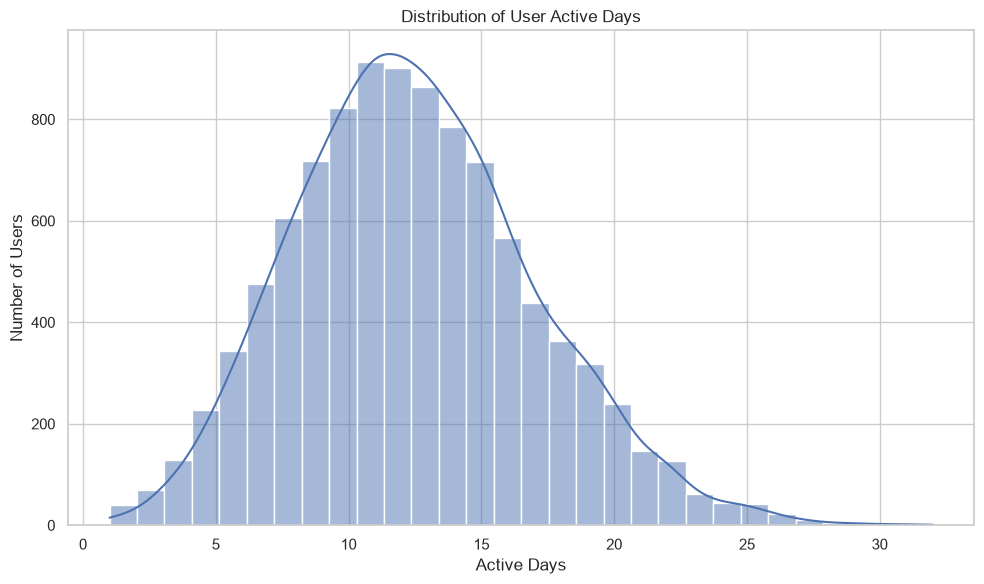

In [15]:
if "active_days" in df_user_engagement.columns:

    plt.figure(figsize=(10, 6))

    sns.histplot(
        data=df_user_engagement,
        x="active_days",
        bins=30,
        kde=True
    )

    plt.title("Distribution of User Active Days")
    plt.xlabel("Active Days")
    plt.ylabel("Number of Users")

    plt.tight_layout()
    plt.show()

### Analyze total API requests:

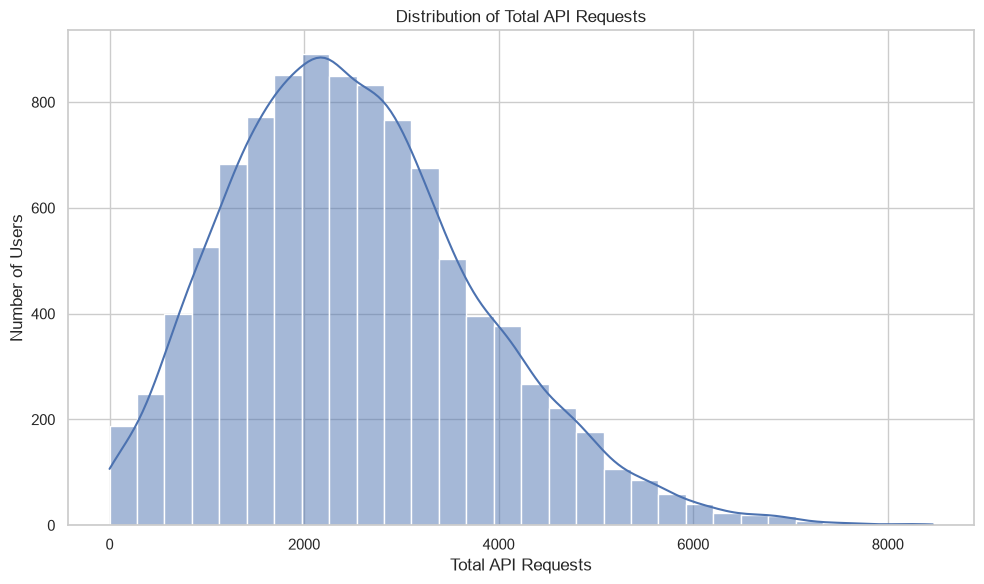

In [16]:
if "total_api_requests" in df_user_engagement.columns:

    plt.figure(figsize=(10, 6))

    sns.histplot(
        data=df_user_engagement,
        x="total_api_requests",
        bins=30,
        kde=True
    )

    plt.title("Distribution of Total API Requests")
    plt.xlabel("Total API Requests")
    plt.ylabel("Number of Users")

    plt.tight_layout()
    plt.show()

### Analyze the relationship between activity metrics:

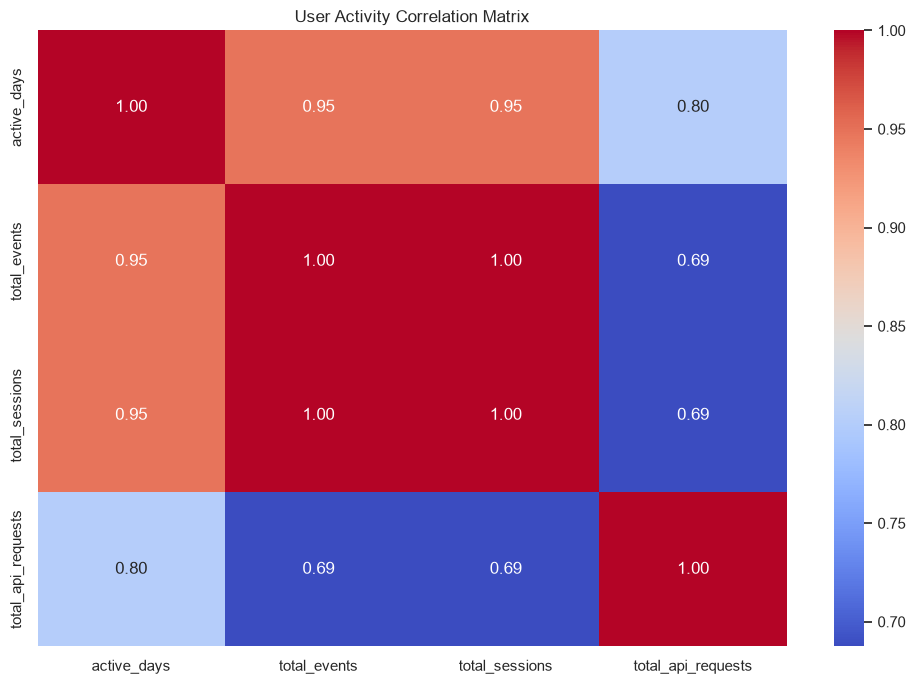

In [17]:
numeric_activity = df_user_engagement[
    available_activity_columns
]

correlation_matrix = numeric_activity.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("User Activity Correlation Matrix")
plt.tight_layout()
plt.show()

### Save your analysis reports:

In [18]:
os.makedirs("../data", exist_ok=True)

activity_summary.to_csv(
    "../data/user_engagement_activity_summary.csv"
)

segment_activity.to_csv(
    "../data/user_engagement_segment_analysis.csv"
)

print("User engagement reports saved successfully.")

User engagement reports saved successfully.


### Save your visualizations:

In [19]:
os.makedirs("../visualizations", exist_ok=True)

In [20]:
import os

os.makedirs("../visualizations", exist_ok=True)

print("Visualization folder is ready.")

Visualization folder is ready.


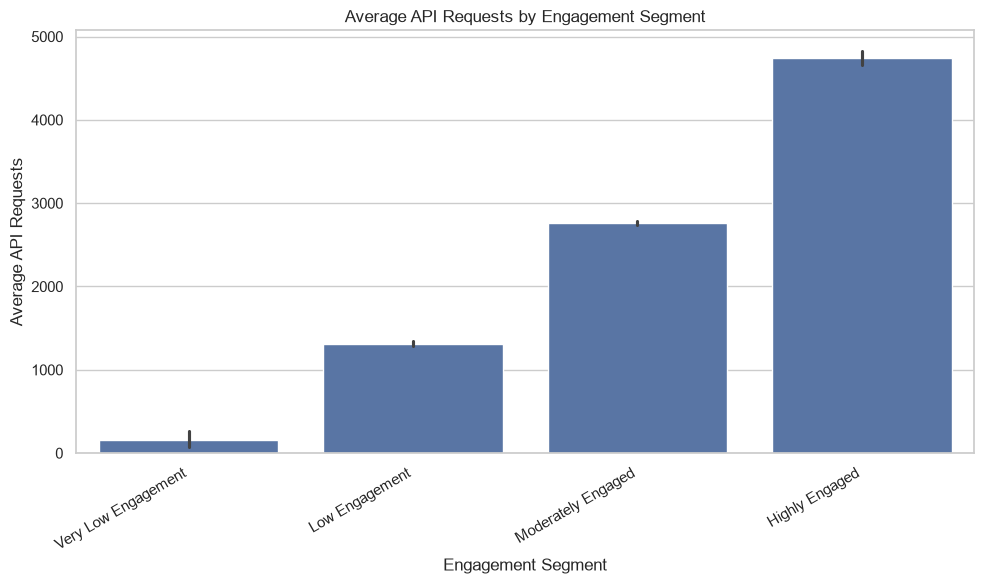

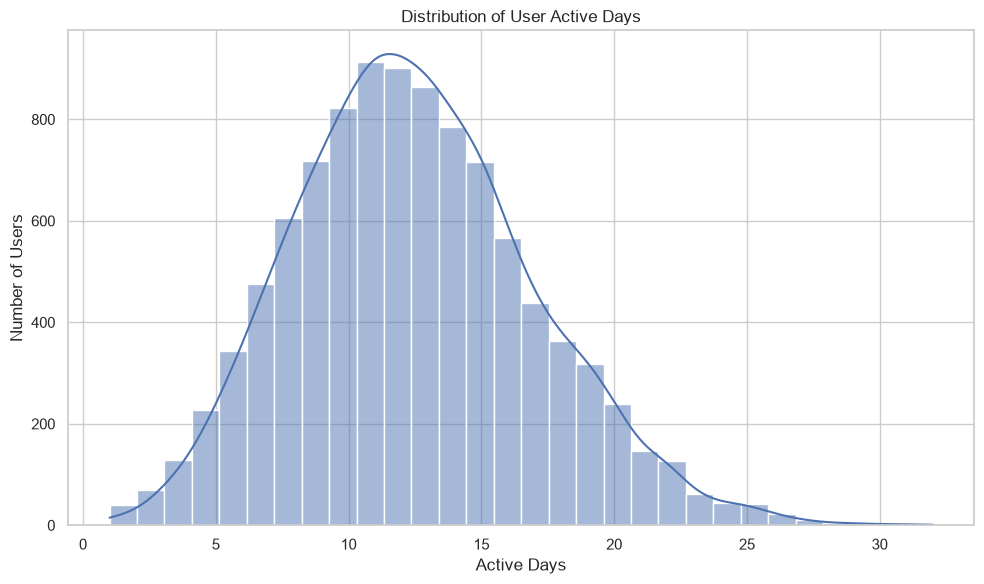

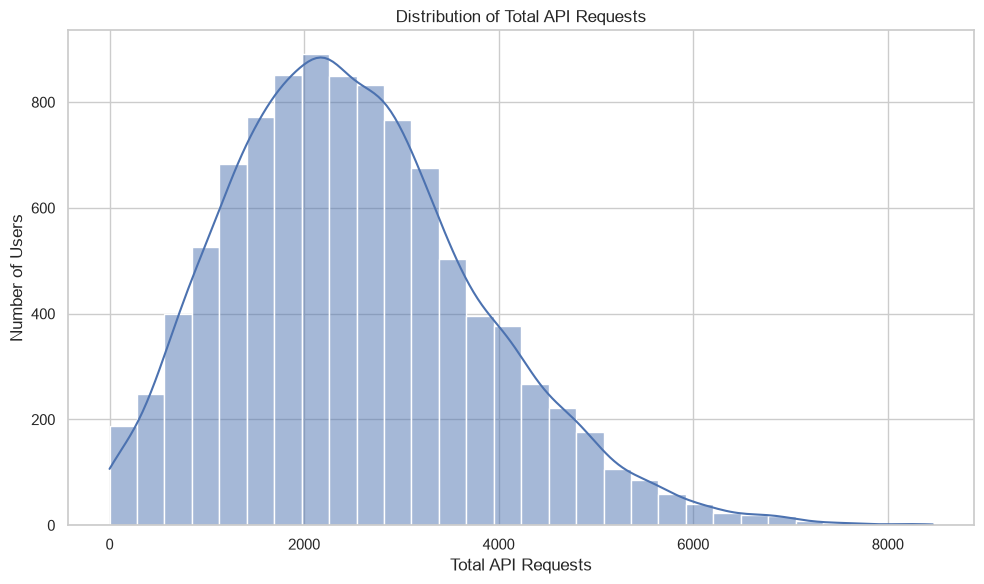

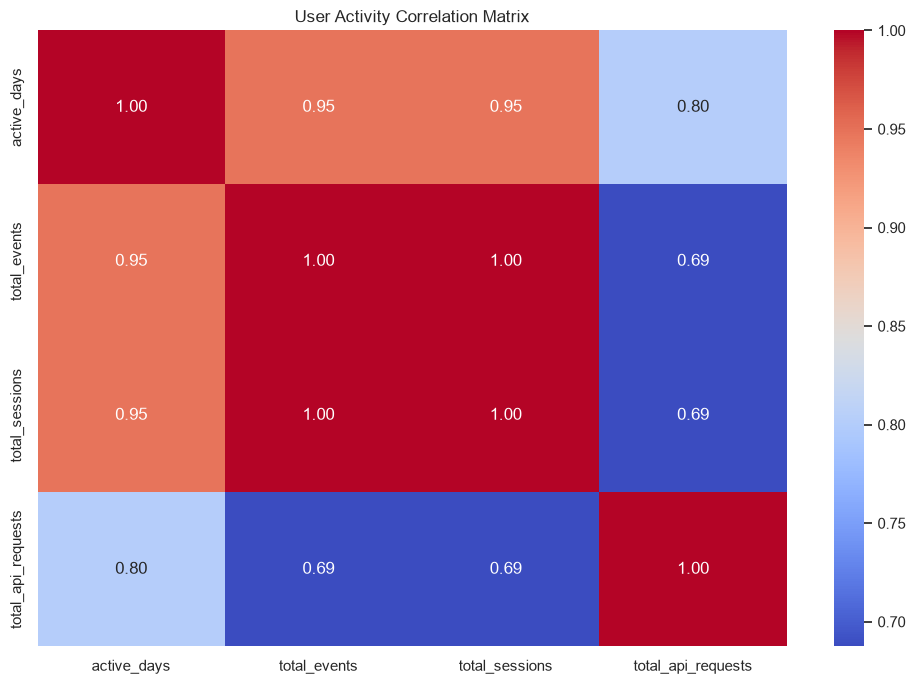

Saved visualization files:
active_days_distribution.png
api_requests_distribution.png
average_api_requests_by_segment.png
user_activity_correlation.png

All visualization charts have been generated and saved.


In [21]:

# ==========================================
# USER ENGAGEMENT EDA - ALL VISUALIZATIONS
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

# Create visualization folder
os.makedirs("../visualizations", exist_ok=True)


# ==========================================
# 1. AVERAGE API REQUESTS BY ENGAGEMENT SEGMENT
# ==========================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df_user_engagement,
    x="engagement_segment",
    y="total_api_requests",
    estimator="mean"
)

plt.title("Average API Requests by Engagement Segment")
plt.xlabel("Engagement Segment")
plt.ylabel("Average API Requests")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()

plt.savefig(
    "../visualizations/average_api_requests_by_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ==========================================
# 2. ACTIVE DAYS DISTRIBUTION
# ==========================================

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_user_engagement,
    x="active_days",
    bins=30,
    kde=True
)

plt.title("Distribution of User Active Days")
plt.xlabel("Active Days")
plt.ylabel("Number of Users")

plt.tight_layout()

plt.savefig(
    "../visualizations/active_days_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ==========================================
# 3. API REQUESTS DISTRIBUTION
# ==========================================

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_user_engagement,
    x="total_api_requests",
    bins=30,
    kde=True
)

plt.title("Distribution of Total API Requests")
plt.xlabel("Total API Requests")
plt.ylabel("Number of Users")

plt.tight_layout()

plt.savefig(
    "../visualizations/api_requests_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ==========================================
# 4. USER ACTIVITY CORRELATION
# ==========================================

activity_columns = [
    "active_days",
    "total_events",
    "total_sessions",
    "total_api_requests"
]

available_activity_columns = [
    col for col in activity_columns
    if col in df_user_engagement.columns
]

numeric_activity = df_user_engagement[
    available_activity_columns
]

correlation_matrix = numeric_activity.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("User Activity Correlation Matrix")

plt.tight_layout()

plt.savefig(
    "../visualizations/user_activity_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ==========================================
# 5. VERIFY SAVED VISUALIZATIONS
# ==========================================

print("Saved visualization files:")

for file in os.listdir("../visualizations"):
    if file.endswith(".png"):
        print(file)

print("\nAll visualization charts have been generated and saved.")


In [22]:
os.makedirs("../visualizations", exist_ok=True)